# 1: Imports and Setup

In [ ]:
!pip install -U ultralytics

In [ ]:
import os
import yaml
import torch
import gdown
import zipfile
from pathlib import Path
from ultralytics import YOLO

# 1. Path Configuration (Portable Root)
# Path.cwd() automatically finds the folder where you run the script
base_path = Path.cwd()
dataset_path = base_path / "vehicle_dataset"
yaml_path = dataset_path / "data.yaml"
zip_destination = base_path / "dataset.zip"

# Google Drive File ID from your link
GDRIVE_FILE_ID = "1gmWwXJmF7L3AY2uMt480dw8LIPEY_Fx7"

# 2. Check and Download Dataset
if not dataset_path.exists():
    print(f"Dataset not found at {dataset_path}. Downloading...")
    url = f"https://drive.google.com/uc?id={GDRIVE_FILE_ID}"

    # Download using gdown
    gdown.download(url, str(zip_destination), quiet=False)

    print("Extracting dataset...")
    with zipfile.ZipFile(zip_destination, "r") as zip_ref:
        zip_ref.extractall(base_path)

    # Clean up zip file
    if zip_destination.exists():
        os.remove(zip_destination)
    print("Dataset ready.")
else:
    print(f"Dataset already exists at {dataset_path}. Skipping download.")

# 3. Check Hardware
cuda_available = torch.cuda.is_available()
print(f"CUDA Available: {cuda_available}")
if cuda_available:
    print(f"Using Device: {torch.cuda.get_device_name(0)}")

# 4. Smart Path Detection for data.yaml
# We check if 'train/images' exists; if not, we fallback to just 'images'
# to prevent the FileNotFoundError you encountered.
train_rel_path = (
    "train/images" if (dataset_path / "train/images").exists() else "images"
)
val_rel_path = "valid/images" if (dataset_path / "valid/images").exists() else "images"

dataset_config = {
    "path": str(dataset_path.absolute()),
    "train": train_rel_path,
    "val": val_rel_path,
    "nc": 1,  # Change this to 1
    "names": ["vehicle"],  # Only include the class you actually have
}

# Ensure directory exists before writing YAML
dataset_path.mkdir(parents=True, exist_ok=True)
with open(yaml_path, "w") as f:
    yaml.dump(dataset_config, f, default_flow_style=False)

print(f"--- Setup Complete ---")
print(f"Root: {base_path}")
print(f"YAML: {yaml_path}")
print(f"Train path set to: {train_rel_path}")

# 2: Load and Train YOLOv5 Model

In [ ]:
model = YOLO("yolov5su.pt")

# 2. Optimized training for T4 GPU (16GB VRAM)
results = model.train(
    data="vehicle_dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=32,  # start safe (NOT 64)
    device=0,  # USE GPU (this is the fix)
    workers=4,
    cache=True,
    amp=True,
    project="/content/drive/MyDrive/yolo_runs",  # save progress
    name="vehicle_exp",
    exist_ok=True,
    pretrained=True,
    optimizer="auto",
    save=True,
    save_period=1,
)

print("Training complete!")
print(results)

# 3: Validate the Trained Model

In [ ]:
val_results = model.val(data="vehicle_dataset/data.yaml", split="test")
print("Validation results:")
print(val_results)

# 4: Predict on Sample Images (Optional)


image 1/1 f:\projects\object-detection-for-traffic-using-yolo\vehicle_dataset\images\test\MVI_40892_00420.jpg: 384x640 19 vehicles, 42.5ms
Speed: 7.3ms preprocess, 42.5ms inference, 24.1ms postprocess per image at shape (1, 3, 384, 640)


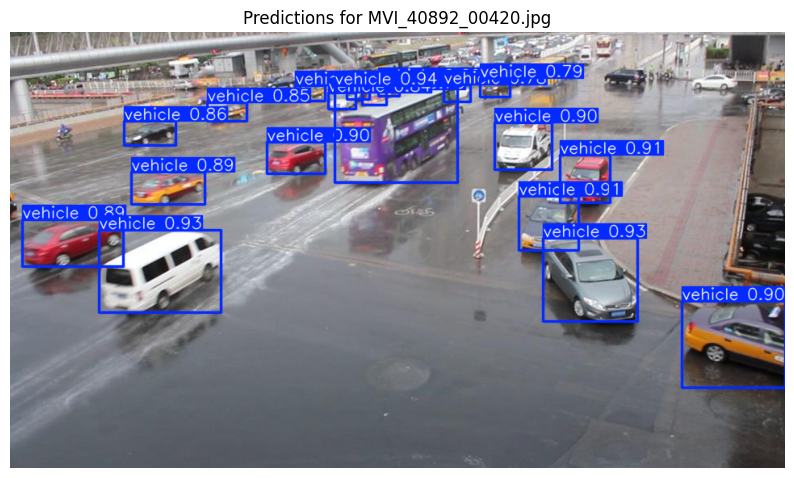

Boxes: tensor([[402.7189,  66.4598, 554.0224, 186.5654],
        [110.9848, 245.6342, 261.5009, 347.0969],
        [660.2169, 255.2094, 777.4477, 358.0760],
        [681.8250, 152.6042, 743.2363, 211.4600],
        [630.7000, 203.1768, 704.0189, 270.1262],
        [600.4802, 112.0067, 671.5464, 170.8814],
        [318.0988, 136.0682, 390.0744, 175.3127],
        [832.0624, 333.3249, 960.0000, 440.3479],
        [ 15.8943, 232.0896, 140.1187, 290.0068],
        [150.2414, 173.1942, 241.8626, 213.8878],
        [141.3385, 110.8323, 205.7123, 140.6456],
        [244.8853,  87.4703, 293.8796, 110.2585],
        [394.5560,  75.2684, 428.0325,  95.6725],
        [353.5721,  66.7537, 390.4309,  85.3313],
        [582.8528,  57.9189, 619.9294,  80.2506],
        [537.1509,  65.7206, 570.4709,  86.4159],
        [436.8060,  71.8406, 466.5558,  90.1975],
        [456.6275,  62.4222, 482.7497,  79.7422],
        [417.5721,  66.0860, 445.2365,  83.1820]], device='cuda:0')
Confidence: tensor([0.936

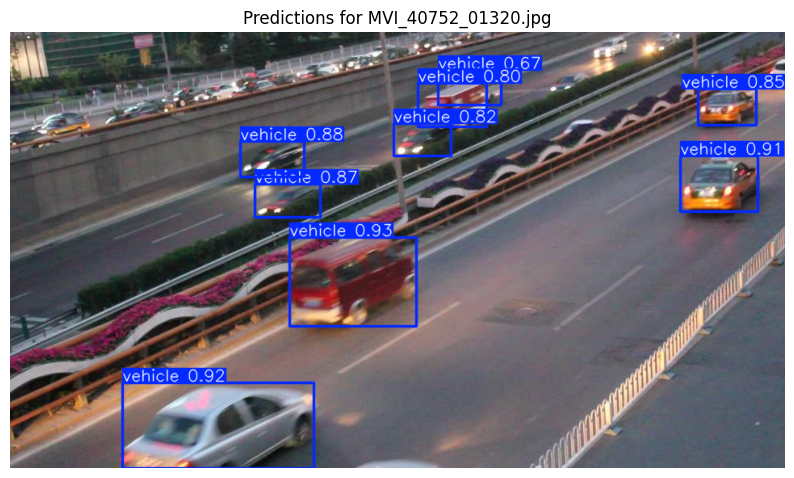

Boxes: tensor([[346.1554, 254.7867, 503.0561, 364.3799],
        [139.9436, 434.6929, 376.8742, 540.0000],
        [830.4958, 153.7472, 926.7626, 222.4211],
        [285.6192, 135.3913, 364.6660, 179.3023],
        [303.5390, 188.4303, 384.6483, 229.3162],
        [852.6863,  70.5668, 924.2677, 115.4897],
        [475.7990, 113.6182, 546.8383, 153.0142],
        [505.8282,  63.8823, 590.1503, 117.5432],
        [530.1996,  47.7961, 608.2628,  90.7564]], device='cuda:0')
Confidence: tensor([0.9328, 0.9211, 0.9124, 0.8779, 0.8684, 0.8538, 0.8186, 0.8015, 0.6721], device='cuda:0')
Class: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0.], device='cuda:0')

image 1/1 f:\projects\object-detection-for-traffic-using-yolo\vehicle_dataset\images\test\MVI_39031_00580.jpg: 384x640 5 vehicles, 12.7ms
Speed: 2.3ms preprocess, 12.7ms inference, 2.2ms postprocess per image at shape (1, 3, 384, 640)


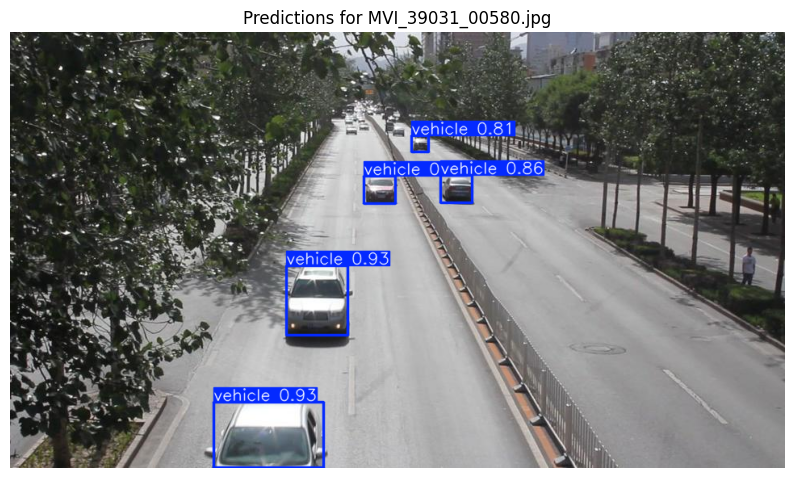

Boxes: tensor([[342.6371, 289.7616, 418.2514, 375.6562],
        [252.0861, 458.2482, 388.6581, 539.8516],
        [533.6449, 177.6548, 572.8156, 211.0694],
        [438.4866, 178.4105, 477.5652, 212.0516],
        [497.2315, 128.7210, 518.6847, 148.5883]], device='cuda:0')
Confidence: tensor([0.9329, 0.9301, 0.8589, 0.8538, 0.8056], device='cuda:0')
Class: tensor([0., 0., 0., 0., 0.], device='cuda:0')

image 1/1 f:\projects\object-detection-for-traffic-using-yolo\vehicle_dataset\images\test\MVI_40962_00960.jpg: 384x640 6 vehicles, 20.3ms
Speed: 4.5ms preprocess, 20.3ms inference, 2.9ms postprocess per image at shape (1, 3, 384, 640)


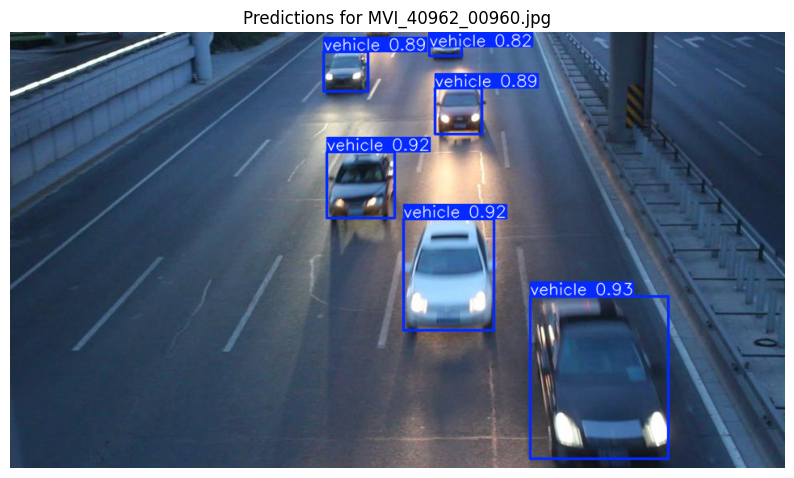

Boxes: tensor([[6.4411e+02, 3.2722e+02, 8.1574e+02, 5.2882e+02],
        [4.8724e+02, 2.3147e+02, 5.9951e+02, 3.6918e+02],
        [3.9207e+02, 1.4875e+02, 4.7626e+02, 2.3007e+02],
        [5.2665e+02, 6.9265e+01, 5.8491e+02, 1.2690e+02],
        [3.8870e+02, 2.4796e+01, 4.4373e+02, 7.3418e+01],
        [5.1979e+02, 7.9491e-01, 5.5942e+02, 2.9480e+01]], device='cuda:0')
Confidence: tensor([0.9277, 0.9248, 0.9232, 0.8895, 0.8876, 0.8204], device='cuda:0')
Class: tensor([0., 0., 0., 0., 0., 0.], device='cuda:0')

image 1/1 f:\projects\object-detection-for-traffic-using-yolo\vehicle_dataset\images\test\MVI_40905_01060.jpg: 384x640 12 vehicles, 16.8ms
Speed: 3.4ms preprocess, 16.8ms inference, 3.7ms postprocess per image at shape (1, 3, 384, 640)


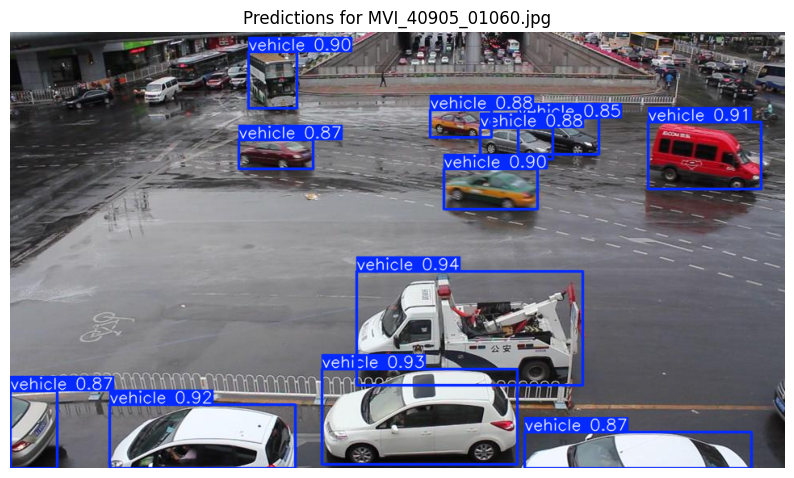

Boxes: tensor([[429.0028, 296.0934, 709.4072, 437.2039],
        [386.5749, 417.4971, 628.4066, 535.4721],
        [123.8422, 461.2635, 353.5561, 540.0000],
        [790.6313, 111.6126, 930.2342, 194.7048],
        [537.0680, 169.9509, 653.9900, 219.9202],
        [295.1035,  24.3207, 355.8557,  94.9938],
        [520.6172,  96.7387, 596.4952, 130.2227],
        [582.1378, 118.8989, 672.4513, 157.5691],
        [283.8893, 133.2545, 375.7020, 169.1005],
        [  0.0000, 444.7458,  58.1419, 540.0000],
        [637.6489, 495.1087, 918.0363, 540.0000],
        [629.1158, 106.4362, 729.1184, 151.8105]], device='cuda:0')
Confidence: tensor([0.9392, 0.9301, 0.9200, 0.9091, 0.9049, 0.9018, 0.8828, 0.8819, 0.8750, 0.8739, 0.8686, 0.8451], device='cuda:0')
Class: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], device='cuda:0')

image 1/1 f:\projects\object-detection-for-traffic-using-yolo\vehicle_dataset\images\test\MVI_40732_01580.jpg: 384x640 5 vehicles, 12.5ms
Speed: 2.5ms preproce

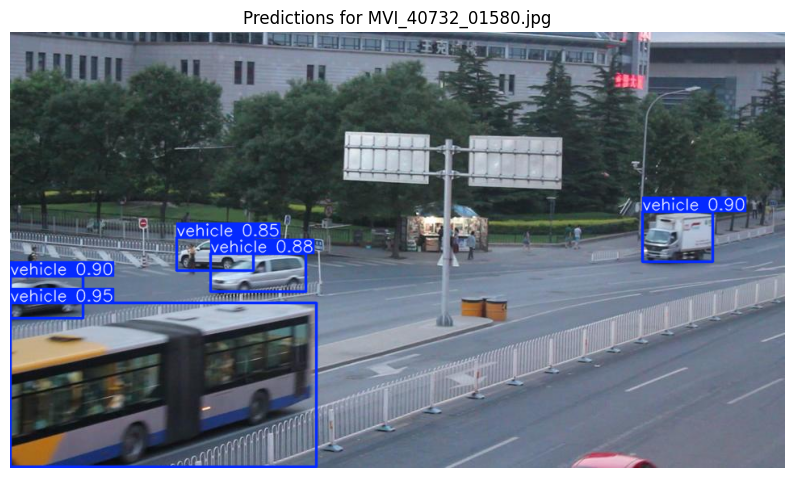

Boxes: tensor([[5.9734e-01, 3.3507e+02, 3.7993e+02, 5.3842e+02],
        [7.8310e+02, 2.2271e+02, 8.7091e+02, 2.8496e+02],
        [0.0000e+00, 3.0239e+02, 9.0854e+01, 3.5406e+02],
        [2.4825e+02, 2.7441e+02, 3.6697e+02, 3.2172e+02],
        [2.0659e+02, 2.5474e+02, 3.0166e+02, 2.9500e+02]], device='cuda:0')
Confidence: tensor([0.9506, 0.8973, 0.8968, 0.8810, 0.8458], device='cuda:0')
Class: tensor([0., 0., 0., 0., 0.], device='cuda:0')

image 1/1 f:\projects\object-detection-for-traffic-using-yolo\vehicle_dataset\images\test\MVI_40892_00900.jpg: 384x640 19 vehicles, 14.6ms
Speed: 2.2ms preprocess, 14.6ms inference, 2.7ms postprocess per image at shape (1, 3, 384, 640)


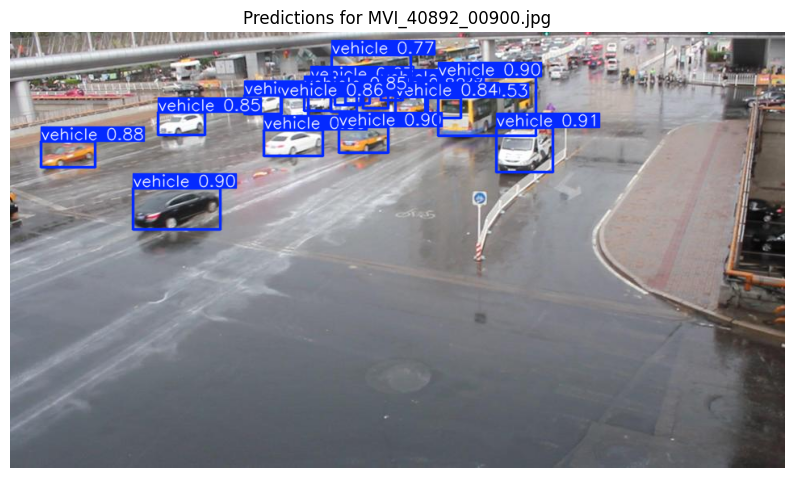

Boxes: tensor([[602.6307, 118.4022, 672.3710, 173.9463],
        [530.2367,  55.7846, 651.9059, 128.0217],
        [407.1833, 117.5240, 468.7305, 149.1016],
        [152.4353, 193.5623, 260.6069, 244.5179],
        [314.5157, 121.0807, 387.6139, 153.7022],
        [ 38.7404, 135.9727, 105.0154, 167.6703],
        [335.8926,  80.1558, 369.3116, 108.1817],
        [183.8015,  99.5975, 241.8678, 127.8343],
        [364.0915,  72.3570, 397.7899,  97.7256],
        [290.5298,  78.0136, 336.9625, 101.0841],
        [477.8561,  80.6299, 517.9945, 104.2795],
        [437.5065,  73.8323, 468.7165,  94.5916],
        [397.3156,  77.5376, 429.5929,  98.6470],
        [398.1406,  28.0338, 496.5812,  78.1010],
        [459.9542,  64.8644, 486.8641,  84.1184],
        [372.7798,  60.6583, 405.1910,  80.6003],
        [415.5356,  68.4643, 445.1868,  88.8547],
        [402.4088,  66.9014, 434.4411,  90.1964],
        [514.4911,  81.1451, 558.7026, 106.1485]], device='cuda:0')
Confidence: tensor([0.905

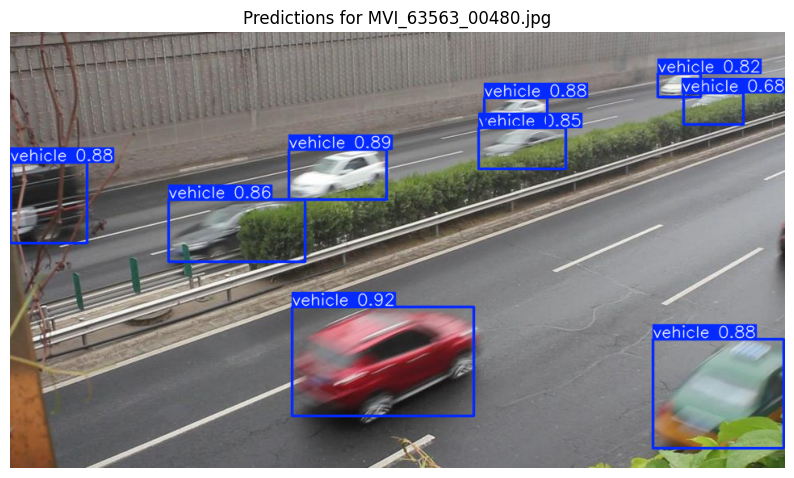

Boxes: tensor([[3.4938e+02, 3.4057e+02, 5.7440e+02, 4.7574e+02],
        [3.4546e+02, 1.4569e+02, 4.6602e+02, 2.0761e+02],
        [5.8777e+02, 8.1098e+01, 6.6561e+02, 1.1789e+02],
        [1.6426e-01, 1.6155e+02, 9.5197e+01, 2.6189e+02],
        [7.9661e+02, 3.8021e+02, 9.5840e+02, 5.1537e+02],
        [1.9687e+02, 2.0770e+02, 3.6503e+02, 2.8417e+02],
        [5.8060e+02, 1.1858e+02, 6.8878e+02, 1.6952e+02],
        [8.0205e+02, 5.1199e+01, 8.5526e+02, 8.0943e+01],
        [8.3476e+02, 7.5983e+01, 9.0800e+02, 1.1417e+02]], device='cuda:0')
Confidence: tensor([0.9189, 0.8935, 0.8816, 0.8791, 0.8759, 0.8642, 0.8456, 0.8237, 0.6795], device='cuda:0')
Class: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0.], device='cuda:0')

image 1/1 f:\projects\object-detection-for-traffic-using-yolo\vehicle_dataset\images\test\MVI_39031_01120.jpg: 384x640 6 vehicles, 12.7ms
Speed: 2.0ms preprocess, 12.7ms inference, 3.4ms postprocess per image at shape (1, 3, 384, 640)


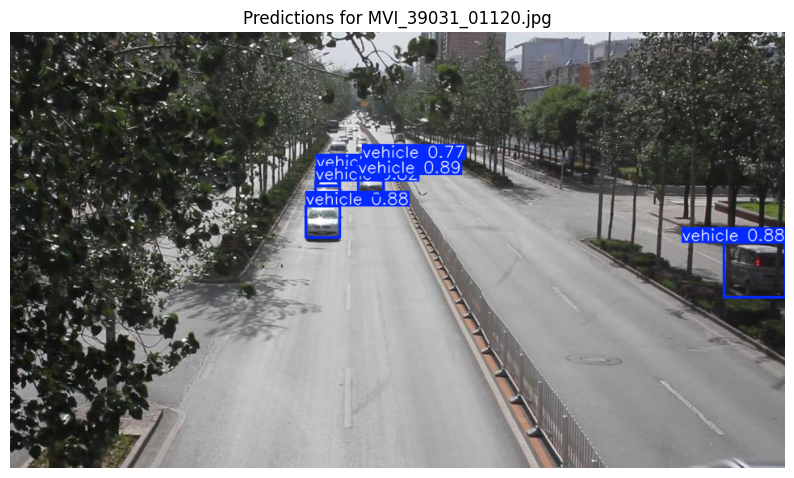

Boxes: tensor([[431.9860, 176.2622, 462.9424, 202.4758],
        [366.5730, 215.1878, 408.1146, 254.4211],
        [884.0962, 260.8972, 960.0000, 328.8672],
        [378.3363, 184.3593, 408.8011, 213.3604],
        [436.5651, 157.9163, 460.8037, 178.8123],
        [379.3109, 169.4395, 407.0811, 190.9245]], device='cuda:0')
Confidence: tensor([0.8859, 0.8835, 0.8815, 0.8235, 0.7709, 0.7145], device='cuda:0')
Class: tensor([0., 0., 0., 0., 0., 0.], device='cuda:0')

image 1/1 f:\projects\object-detection-for-traffic-using-yolo\vehicle_dataset\images\test\MVI_40904_00860.jpg: 384x640 12 vehicles, 12.7ms
Speed: 2.7ms preprocess, 12.7ms inference, 2.4ms postprocess per image at shape (1, 3, 384, 640)


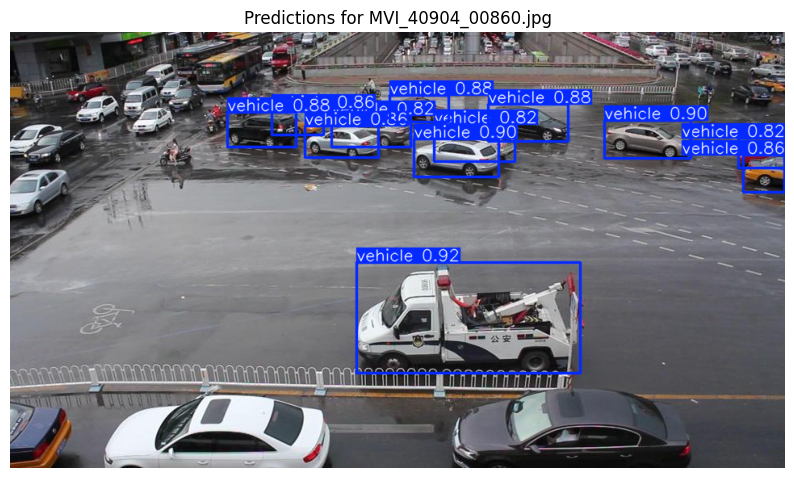

Boxes: tensor([[429.3398, 285.3900, 706.7269, 422.1942],
        [500.4473, 132.4191, 605.9933, 179.4727],
        [736.1161, 109.4864, 843.4877, 156.6634],
        [592.3651,  89.0447, 691.3819, 135.2077],
        [470.1125,  78.2964, 543.0064, 111.7387],
        [269.3626,  99.6488, 354.8138, 142.5861],
        [324.9156,  95.5500, 388.6068, 127.8831],
        [365.9059, 116.5162, 456.4124, 155.2937],
        [908.4326, 152.2767, 959.7189, 198.6208],
        [398.4890, 103.9564, 496.3784, 142.8038],
        [902.0911, 131.7812, 960.0000, 168.0919],
        [525.8741, 114.4881, 625.1391, 160.1656]], device='cuda:0')
Confidence: tensor([0.9161, 0.8987, 0.8984, 0.8821, 0.8814, 0.8813, 0.8635, 0.8584, 0.8561, 0.8232, 0.8170, 0.8160], device='cuda:0')
Class: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], device='cuda:0')


In [1]:
from ultralytics import YOLO
import os
import random
import matplotlib.pyplot as plt
import cv2

# Load your trained model
model = YOLO("models/yolov5_1k.pt")  # adjust path

# Path to test images folder
test_folder = "vehicle_dataset/images/test/"

# Get all image files in the folder
all_images = [
    os.path.join(test_folder, f)
    for f in os.listdir(test_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Pick 10 random images
test_images = random.sample(all_images, min(10, len(all_images)))

# Run inference and display
for img_path in test_images:
    results = model.predict(
        source=img_path, conf=0.5, save=False
    )  # save=False, we just display
    annotated_img = results[0].plot()  # draw boxes
    annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(annotated_img)
    plt.title(f"Predictions for {os.path.basename(img_path)}")
    plt.axis("off")
    plt.show()

    # Print box info
    for result in results:
        print("Boxes:", result.boxes.xyxy)
        print("Confidence:", result.boxes.conf)
        print("Class:", result.boxes.cls)